# Experimental study of Simulated Annealing for vehicle routing

## 1. Objectives

This report examines solution quality, variability and search effort. It investigates temperature selection on reserved Solomon instances, performance on separate Solomon tests, the effect of longer budgets on larger Homberger cases, and execution on one synthetic 10,000-customer case.

The three studies use different protocols and are reported separately. All counts exclude the depot. The displayed results are measured observations, not theoretical performance guarantees.


## 2. Problem and method

### 2.1. Routing problem

Every customer must appear in exactly one route. Vehicles start and return to the depot, respect capacity, and satisfy customer and depot time windows. The supplied fleet limit is also enforced. The objective is **total travel distance**:

$$C = \sum_{r \in R}\sum_{(i,j)\in r} d_{ij}.$$

Waiting is allowed when a vehicle arrives early. Waiting and vehicle count are not added to the objective. The synthetic case omits time windows and therefore solves a simpler CVRP rather than the full benchmark CVRPTW.

### 2.2. Simulated Annealing

SA constructs a feasible starting solution, then proposes relocate, swap, segment reversal, short-chain and route-tail exchange moves. Infeasible moves are rejected. Feasible improvements are accepted; a worsening move of cost increase $\Delta$ is accepted with probability $\exp(-\Delta/T)$. The current solution can worsen during exploration, while the best feasible solution is kept separately.

For a timed search, $T(t)=T_0(T_f/T_0)^{t/L}$, with $T_0=\max(1,fC_0)$. Here $f$ is the starting factor, $C_0$ the starting cost, $T_f$ the final temperature and $L$ the runtime budget. With no time cutoff, the same exponential schedule follows the fraction of proposed moves completed. Rejected proposals still count. Temperature updates occur between batches of 256 attempts.

### 2.3. Implementation and assumptions

The shared Python implementation uses compiled Numba move batches, cached route costs and an independent final feasibility check. Compilation is outside measured search time. Benchmark runtime includes construction, search and final validation.

Benchmarks use complete Euclidean travel costs: every customer pair is directly reachable. This is an approximation of a road network. An incomplete road network would require shortest-path travel costs and explicit handling of disconnected pairs. NetworkX proximity edges describe the synthetic layout, not restrictions on its routes. Dense distance storage grows quadratically; the 10,001-node matrix alone needs about 0.80 GB.

The implementation is in [sa.py](../src/cvrp/sa.py), [sa_static.py](../src/cvrp/sa_static.py) and [sa_vrptw.py](../src/cvrp/sa_vrptw.py).


## 3. Experimental design

### 3.1. Data and budgets

| Study | Cases | Seeds | Budget | Runs |
| --- | --- | --- | --- | --- |
| Temperature selection | Six reserved Solomon cases | 101, 102 | 20 s | 144 |
| Solomon test | The other 50 Solomon cases | 1–10 | 20 s | 500 |
| Homberger | R1_4_1, R1_8_1, R1_10_1 | 1–3 | 20, 60, 120 s | 27 |
| Synthetic | 10,000 customers | 1 | 10 million moves | 1 |

Solomon includes clustered (C), random (R) and mixed (RC) scenarios. Tuning uses C101, C201, R101, R201, RC101 and RC201. Test cases never select the settings. Earlier exploratory work did examine some test cases, so this is not fully blind validation.

### 3.2. Factors and controls

Temperature selection varies the starting factor (0.0025, 0.005, 0.01) and final temperature (0.005, 0.01, 0.02, 0.05). The Homberger study varies case and runtime while keeping the selected temperatures fixed. Seeds are matched across budgets. Longer budgets also slow cooling, so both effects are part of the comparison.

Seeds provide repetitions, not a different search method. Solomon uses up to seven workers and Homberger three, with one solver process per job. Hardware, machine load and stopping time affect timed trajectories even for identical seeds. The campaigns were recorded separately, so their absolute throughput is not a controlled cross-campaign hardware comparison.

### 3.3. Quality and time measures

**Mean gap (%)** averages `100 × (cost / reference cost − 1)` across seeds. **Best gap (%)** is the smallest observed gap. **SD gap (%)** is sample standard deviation, measuring dispersion rather than statistical significance. A feasible best-known reference is an upper bound for minimization, not a proven optimum.

Homberger also has a mathematical lower bound: the larger of its minimum spanning tree cost and `2 × ceil(total demand / capacity) × cheapest depot edge`. A route union connects every node, while capacity forces at least that many depot-return routes. These bounds relax time windows and may be weak; reference gaps must not be confused with excess over this lower bound.

**Time (s)** is a runtime allowance. **CPU (s)** measures process CPU time around a warmed solver call. **Best found (s)** is the batch-snapshot discovery time of the final observed best. **Moves** counts all proposed attempts, including rejections. A cutoff and a final discovery time are not proofs of convergence.

### 3.4. Data checks and report reproduction

Solomon and Homberger distances and travel times are truncated to one decimal to match the reference files. References were checked for coverage, capacity, time windows, fleet feasibility and cost. Depot service is zero. Benchmark starting routes never use reference routes. Failed runs would remain visible with undefined gaps.

This notebook reloads saved measurements and rebuilds the analysis quickly; it does not silently rerun the expensive campaigns. The preserved experiment notebook linked at the end contains the original execution cells. Solomon rows retain their original display precision, while Homberger rows are saved at full precision. Per-run tuning records were not retained in the old display, so tuning analysis uses its saved condition means.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image

ROOT = Path.cwd().resolve()
while not (ROOT / 'notebooks/data/sa_study_results.json').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / 'notebooks/data'
saved = json.loads((DATA / 'sa_study_results.json').read_text(encoding='utf-8'))
solomon = pd.DataFrame(saved['solomon_runs'])
per_case = pd.DataFrame(saved['solomon_summary'])
homberger = pd.DataFrame(saved['homberger_runs'])
pd.set_option('display.float_format', '{:.3f}'.format)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})
assert len(solomon) == 500 and len(homberger) == 27
assert not solomon.duplicated(['instance', 'seed']).any()
assert not homberger.duplicated(['instance', 'seed', 'time_limit']).any()
assert solomon.groupby('instance').seed.nunique().eq(10).all()
assert np.allclose(solomon.gap, 100*(solomon.cost/solomon.best_known-1), atol=0.001, rtol=0)
assert np.allclose(homberger.gap, 100*(homberger.cost/homberger.best_known-1), atol=1e-6, rtol=0)
assert solomon.feasible.all() and homberger.feasible.all()


## 4. Temperature selection

### 4.1. Protocol

Twelve parameter combinations run on six reserved cases with two seeds. The setting with the lowest mean gap is selected. The table groups the four final-temperature choices under each starting factor. Its range is across **condition means**, each based on 12 runs; it is not the range of individual outcomes.

### 4.2. Results


In [2]:
conditions = pd.DataFrame(saved['tuning_conditions'])
factor = conditions.groupby('start_factor').mean_gap.agg(['mean', 'min', 'max']).reset_index()
display(factor.rename(columns={'start_factor': 'Start factor', 'mean': 'Mean gap (%)',
    'min': 'Lowest mean gap (%)', 'max': 'Highest mean gap (%)'}).round(3))


,Start factor,Mean gap (%),Lowest mean gap (%),Highest mean gap (%)
0,0.002,0.608,0.552,0.708
1,0.005,0.572,0.544,0.599
2,0.010,0.514,0.427,0.563


### 4.3. Observations

The selected pair is **start factor 0.01 and final temperature 0.005**, with a recorded mean tuning gap of **0.427%**. Over the four final-temperature choices, factor 0.01 has the smallest average gap (about 0.514%), compared with 0.572% for 0.005 and 0.608% for 0.0025.

This supports the selected pair among the tested candidates on this fixed tuning set. It does not prove universal optimality or guarantee transfer to larger cases. The tuning mean is not a test score. No seed-level tuning SD is invented from the aggregate ranking.


## 5. Solomon test study

### 5.1. Protocol

The selected pair is applied to 50 different cases, ten seeds per case, for 20 seconds. All 500 solutions passed the original independent feasibility checks. The family table uses one mean per instance; its SD measures differences **between instances**. Error bars for individual cases instead show variation **between ten seeds**.

### 5.2. Results


,Group,Instances,Mean gap (%),SD gap (%)
0,C1,8,0.368,0.572
1,C2,7,0.533,1.004
2,R1,11,1.403,0.790
3,R2,10,2.162,0.602
4,RC1,7,2.122,1.052
5,RC2,7,2.297,0.432


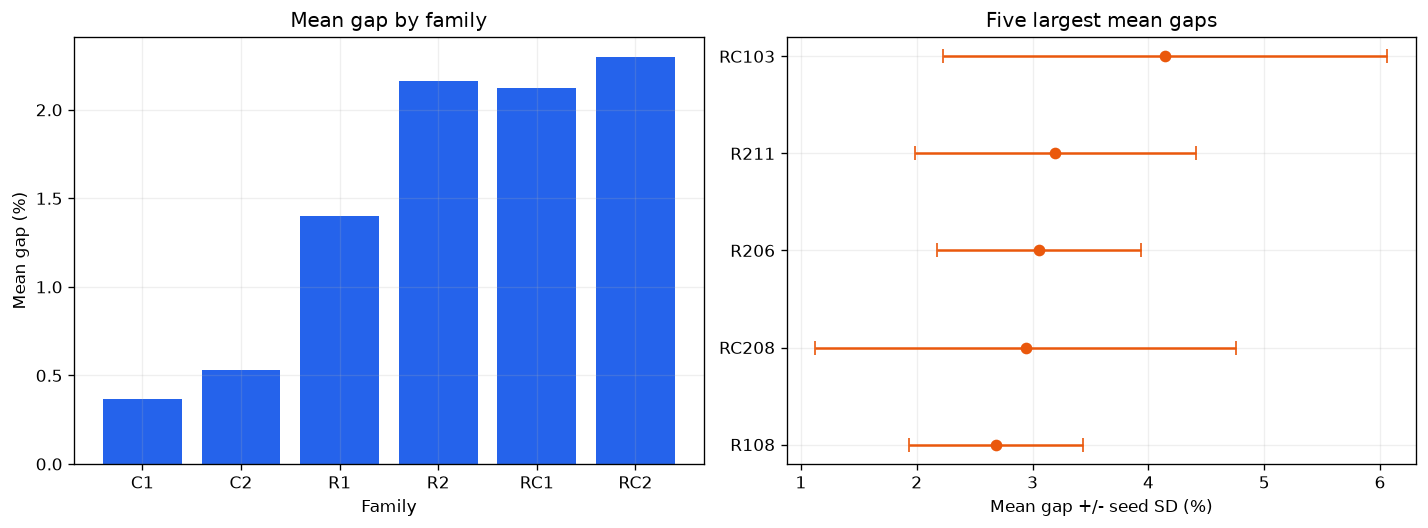

In [3]:
CLASSES = ['C1', 'C2', 'R1', 'R2', 'RC1', 'RC2']
per_case['Group'] = per_case.instance.str[:-2]
family = per_case.groupby('Group').agg(instances=('instance', 'size'),
    mean_gap=('gap_mean', 'mean'), sd_gap=('gap_mean', 'std')).reindex(CLASSES)
display(family.reset_index().rename(columns={'instances': 'Instances',
    'mean_gap': 'Mean gap (%)', 'sd_gap': 'SD gap (%)'}).round(3))
hardest = per_case.nlargest(5, 'gap_mean').sort_values('gap_mean')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(family.index, family.mean_gap, color='#2563eb')
axes[0].set(title='Mean gap by family', xlabel='Family', ylabel='Mean gap (%)')
axes[1].errorbar(hardest.gap_mean, np.arange(5), xerr=hardest.gap_std,
    fmt='o', capsize=4, color='#ea580c')
axes[1].set_yticks(np.arange(5), hardest.instance)
axes[1].set(title='Five largest mean gaps', xlabel='Mean gap +/- seed SD (%)')
fig.tight_layout()
plt.show()


### 5.3. Observations

The overall mean gap is **1.493%**, with **500/500 feasible runs**. At least one seed matches the supplied reference within reported precision on **16/50 cases**. C1 and C2 have lower means (about 0.368% and 0.533%) than R2 and RC2 (about 2.162% and 2.297%).

Clustered cases are easier for this tested configuration than several random or mixed cases. Distribution alone is not isolated: capacities and time windows also differ. The individual-case error bars show why one seed can give an incomplete picture.

Mean recorded runtime is **20.000 seconds**, with about **57.55 million attempts** per run. Because runtime is controlled by the cutoff, a flat runtime distribution is not evidence of convergence. Such a histogram has been omitted.


### 5.4. Example trajectory

This recorded RC101 run illustrates the route solution and best distance over time. It uses seed 1 and the default temperatures (factor 0.005, final temperature 0.02), before parameter selection; it is not an extra observation in the 500-run campaign. It returned distance 1640.9, gap 1.303% and 17 routes in about 20 seconds. Flat sections mean no new best was recorded, not that further improvement is impossible.


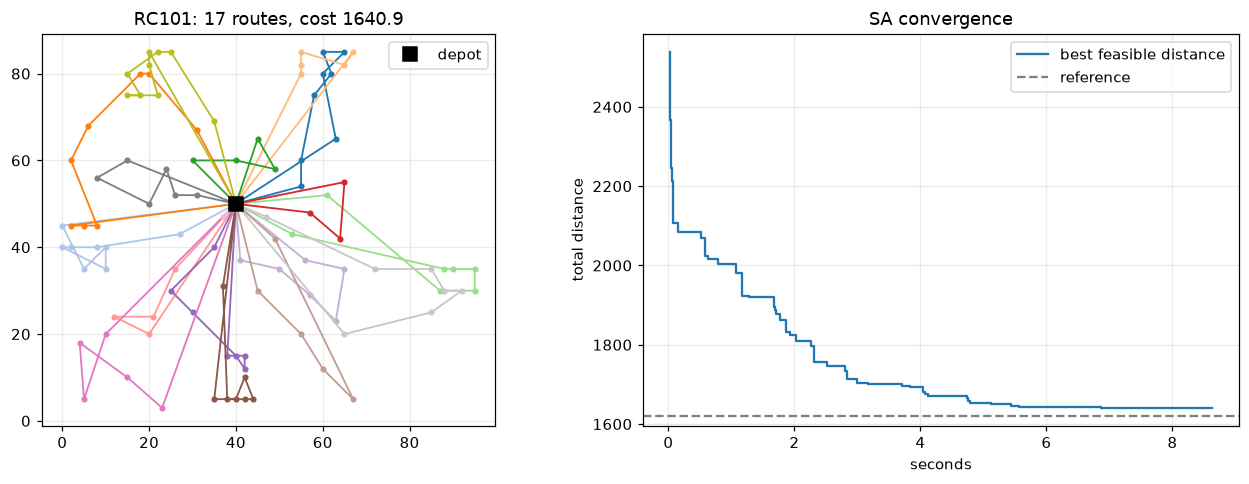

In [4]:
display(Image(filename=str(DATA / 'rc101_example.png')))


## 6. Homberger time-budget study

### 6.1. Cases and protocol

Each R1 case runs with seeds 1–3 at 20, 60 and 120 seconds: 27 runs. Temperature settings remain 0.01 and 0.005. Increasing the budget also slows cooling. Capacity is 200 for all three cases; fleet limits are 100, 200 and 250. Areas and depot deadlines differ, so customer count is not the only changing problem factor. Depot limits use problem time units, not CPU seconds.


In [5]:
case_info = homberger.groupby(['n', 'instance']).agg(
    reference=('best_known', 'first'), bound=('lower_bound', 'first')).reset_index()
case_info['Area'] = ['199 x 196', '400 x 399', '500 x 499']
case_info['Depot limit'] = [804, 1688, 1925]
display(case_info[['instance', 'n', 'Area', 'Depot limit', 'reference', 'bound']].rename(columns={
    'instance': 'Instance', 'n': 'Customers', 'reference': 'Reference cost', 'bound': 'Lower bound'}).round(1))


,Instance,Customers,Area,Depot limit,Reference cost,Lower bound
0,R1_4_1,400,199 x 196,804,10305.800,2603.800
1,R1_8_1,800,400 x 399,1688,36345.000,7412.700
2,R1_10_1,1000,500 x 499,1925,53026.100,10253.200


### 6.2. Quality results

Each table row summarizes three seeds. **Valid runs** counts successful runs out of three; quality statistics describe feasible outcomes. Error bars show sample SD, not a significance test. The paired-seed design compares the same initial random seed at each budget, without assuming that longer search must always improve.


,Customers,Time (s),Best gap (%),Mean gap (%),SD gap (%),Valid runs
0,400,20.000,6.205,6.542,0.294,3/3
1,400,60.000,2.974,3.457,0.460,3/3
2,400,120.000,2.175,2.821,0.589,3/3
3,800,20.000,12.484,13.039,0.709,3/3
4,800,60.000,6.894,8.003,1.030,3/3
5,800,120.000,6.328,6.470,0.131,3/3
6,1000,20.000,16.547,17.387,0.735,3/3
7,1000,60.000,9.962,10.743,1.014,3/3
8,1000,120.000,7.833,8.207,0.510,3/3


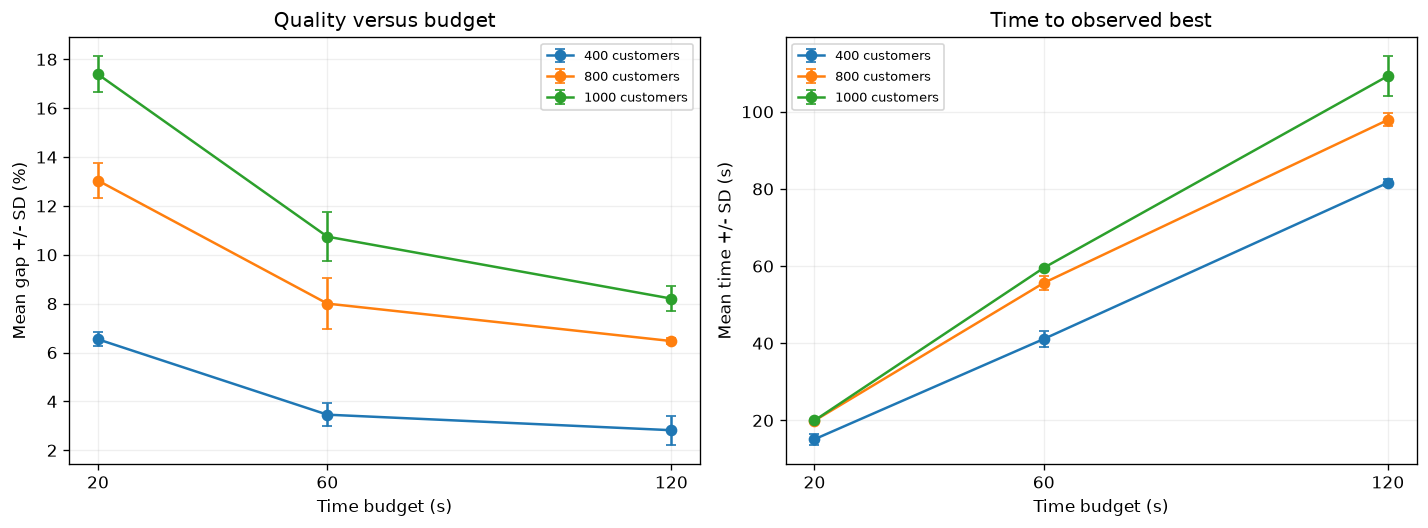

In [6]:
hs = homberger.groupby(['n', 'time_limit'], as_index=False).agg(
    best_gap=('gap', 'min'), mean_gap=('gap', 'mean'), sd_gap=('gap', 'std'), valid=('feasible', 'sum'),
    cpu=('cpu_seconds', 'mean'), best_time=('time_to_best', 'mean'),
    best_time_sd=('time_to_best', 'std'), moves=('iterations', 'mean'))
quality = hs[['n', 'time_limit', 'best_gap', 'mean_gap', 'sd_gap', 'valid']].copy()
quality['valid'] = quality.valid.astype(str) + '/3'
display(quality.rename(columns={'n': 'Customers', 'time_limit': 'Time (s)', 'best_gap': 'Best gap (%)',
    'mean_gap': 'Mean gap (%)', 'sd_gap': 'SD gap (%)', 'valid': 'Valid runs'}).round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for size, curve in hs.groupby('n'):
    curve = curve.sort_values('time_limit')
    axes[0].errorbar(curve.time_limit, curve.mean_gap, yerr=curve.sd_gap,
        fmt='o-', capsize=3, label=f'{size} customers')
    axes[1].errorbar(curve.time_limit, curve.best_time, yerr=curve.best_time_sd,
        fmt='o-', capsize=3, label=f'{size} customers')
axes[0].set(title='Quality versus budget', xlabel='Time budget (s)', ylabel='Mean gap +/- SD (%)')
axes[1].set(title='Time to observed best', xlabel='Time budget (s)', ylabel='Mean time +/- SD (s)')
for ax in axes:
    ax.set_xticks([20, 60, 120])
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### 6.3. Observations on quality

Mean gaps decrease from **6.54% to 2.82%** for 400 customers, **13.04% to 6.47%** for 800, and **17.39% to 8.21%** for 1,000 when the budget rises from 20 to 120 seconds. All **27/27 runs are feasible**.

The 20-to-60-second increase gives a larger absolute gain than the subsequent 60-to-120-second increase. This supports insufficient search effort as one contributor to the earlier large gaps, with diminishing marginal gains in these cases. It does not isolate size or establish statistical significance. One R1 case per size and three seeds remain a small study.

The MST dominates both lower-bound components. The bound is valid but weak and relaxes time windows, so the small reference gaps do not certify near-optimality.


### 6.4. Time and search effort

**Time (s)** is the requested budget. **Best found (s)** is the mean discovery time of the final observed best at batch boundaries. **Moves (million)** counts proposals, not accepted improvements. CPU time is per solver process.


In [7]:
effort = hs[['n', 'time_limit', 'cpu', 'best_time', 'moves']].copy()
effort['moves'] /= 1e6
display(effort.rename(columns={'n': 'Customers', 'time_limit': 'Time (s)', 'cpu': 'CPU (s)',
    'best_time': 'Best found (s)', 'moves': 'Moves (million)'}).round(2))


,Customers,Time (s),CPU (s),Best found (s),Moves (million)
0,400,20.000,19.930,15.110,47.920
1,400,60.000,59.840,41.110,160.650
2,400,120.000,119.710,81.610,323.080
3,800,20.000,19.920,19.930,29.800
4,800,60.000,59.880,55.640,104.750
5,800,120.000,119.700,97.890,212.700
6,1000,20.000,19.930,19.980,24.640
7,1000,60.000,59.880,59.560,89.820
8,1000,120.000,119.720,109.270,181.370


### 6.5. Observations on time

On the 1,000-customer case, mean effort rises from **24.6 million** attempts at 20 seconds to **181.4 million** at 120 seconds. At 120 seconds, the final best is first observed after about **109.3 seconds** on average.

CPU time closely tracks the wall-clock allowance, consistent with compute-bound search. Larger budgets allow more attempts and later discoveries. The last discovery is a property of the observed trajectory, not the time required to find an optimum; improvement after the cutoff remains possible.


## 7. Synthetic case with 10,000 customers

### 7.1. Protocol and initial layout

NetworkX generates a uniform layout with graph seed 101: 10,000 customers plus depot 0 at (50, 50). Demands are integers 1–10 and capacity is 100. There are no time windows. Blue points represent customers and the red star marks the depot; proximity edges are hidden for readability.

SA starts from a feasible angular sweep, using seed 1, factor 0.005, final temperature 0.02 and 10 million proposed moves without a time cutoff. Cooling follows move count. Setup and sweep construction occur before the solver timer. Its simpler constraints and stopping rule prevent a direct comparison with the timed CVRPTW tests.


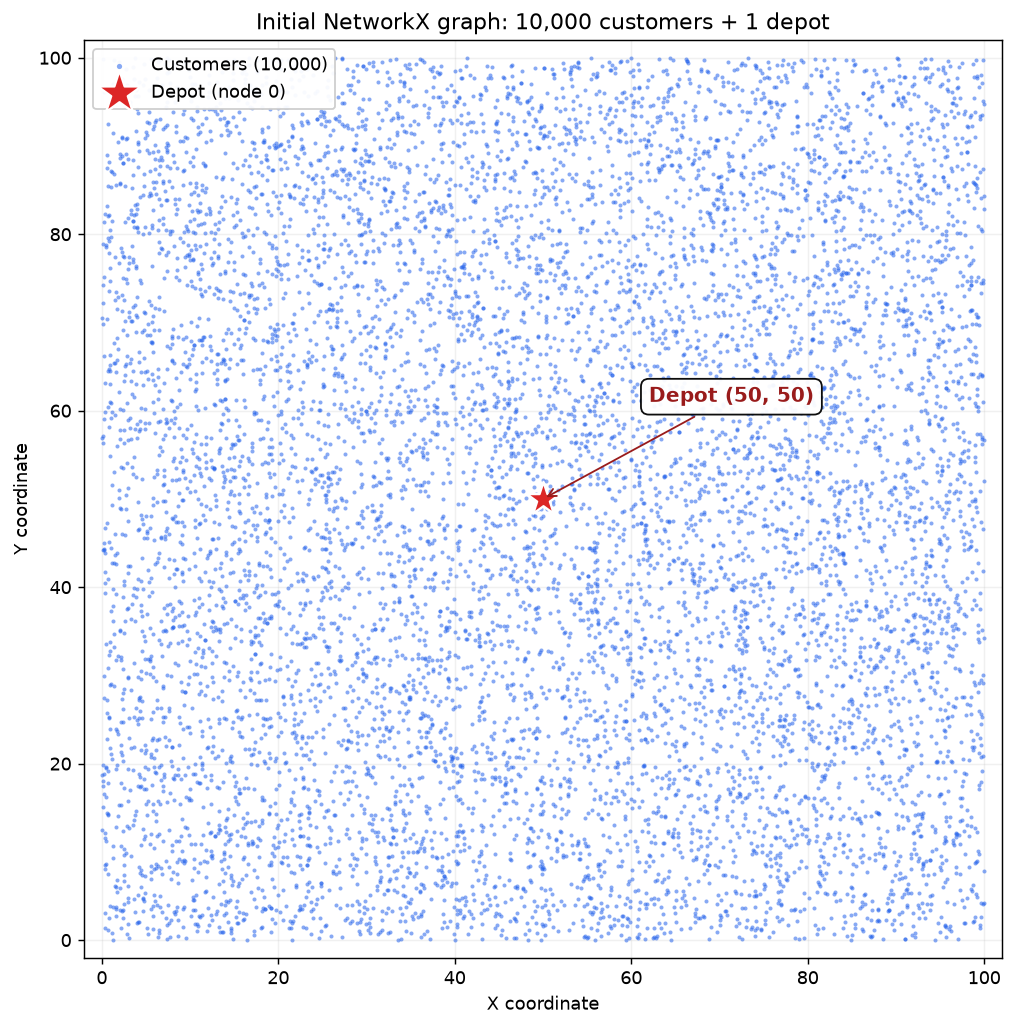

In [8]:
display(Image(filename=str(DATA / 'synthetic_layout.png')))


### 7.2. Results and search behaviour

There is no reference optimum. **Gain (%)** measures reduction from the sweep starting cost, not an optimality gap. The saved diagnostic figure shows best distance, cooling, gain over time and final route loads. Best distance and gain describe the same change from two viewpoints; cooling and loads explain exploration and final capacity use.


,Customers,Start cost,Best cost,Gain (%),Routes,Time (s),Moves
0,10000,189072.080,119173.680,36.970,672,58.300,10000000


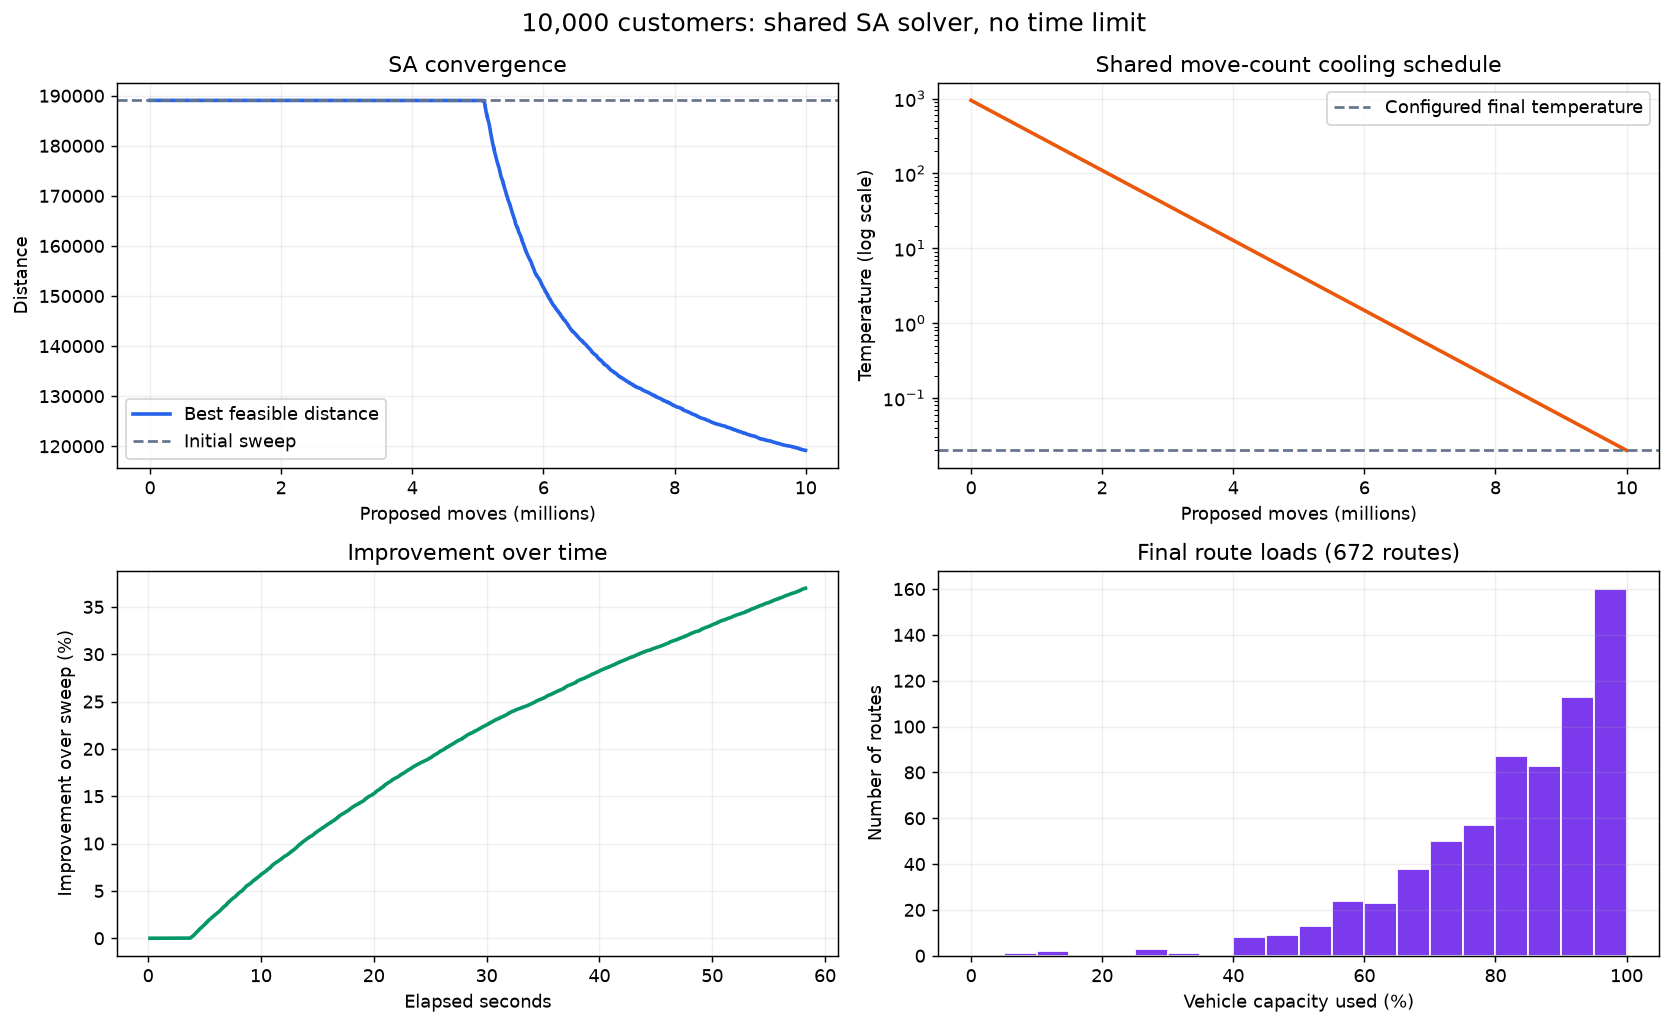

In [9]:
s = saved['synthetic']
display(pd.DataFrame([{'Customers': int(s['customers']), 'Start cost': s['initial_cost'],
    'Best cost': s['cost'], 'Gain (%)': s['improvement_pct'], 'Routes': int(s['routes']),
    'Time (s)': s['seconds'], 'Moves': int(s['iterations'])}]).round(2))
display(Image(filename=str(DATA / 'synthetic_diagnostics.png')))


### 7.3. Observations

Distance falls from **189,072.08 to 119,173.68**, a **36.97% reduction**, with **672 feasible routes**. The run completes all **10 million moves** in about **58.3 seconds**.

The early high-temperature phase explores without immediately improving the saved best. Later cooling favours improving moves and produces the visible reduction. This demonstrates execution on one large case, not optimality or equal performance with time windows. The dense distance matrix remains a memory limitation. Dense all-route maps were removed because they obscured rather than explained the solution.
